# Analysis of the last OpenFAST run
Reads only `IEA-3.4-130-RWT.SFunc.out`, the output that the Simulink model writes in this folder,
and shows its signals and statistics. Use it to follow a simulation before renaming the file and
moving it to `Results/Data/` (main README, Section 7).

In [4]:
# ---------------- Settings ----------------
RUN_FILE = "IEA-3.4-130-RWT.SFunc.out"   # output written by the Simulink model
T_MIN, T_MAX = 200, 5200                  # window for the statistics [s] (paper: 200-5200 s)
ZOOM = (1800, 2200)                       # window for the zoomed plots [s]
P_RATED = 3370                            # rated power [kW]
# -------------------------------------------

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from openfast_toolbox import FASTOutputFile

df = FASTOutputFile(RUN_FILE).toDataFrame()
units = {}
for c in df.columns:
    name, _, unit = c.partition("_")
    units[name] = unit.strip("[]()")
df.columns = [c.partition("_")[0] for c in df.columns]
df = df.drop_duplicates("Time").reset_index(drop=True)

win = df[(df["Time"] >= T_MIN) & (df["Time"] <= T_MAX)]
zoom = df[(df["Time"] >= ZOOM[0]) & (df["Time"] <= ZOOM[1])]
print(f"{RUN_FILE}: {len(df)} samples, t = {df['Time'].iloc[0]:g} to {df['Time'].iloc[-1]:g} s")
if df["Time"].iloc[-1] < T_MAX:
    print(f"Note: the run has not reached {T_MAX} s yet; statistics use the data available.")


def plot(data, pairs, title=None, ncols=2):
    """Plot several channels against time, one per axis, and print their min/max."""
    n = len(pairs)
    nrows = int(np.ceil(n / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3.2 * nrows), squeeze=False)
    for ax, (col, label) in zip(axs.flat, pairs):
        ax.plot(data["Time"], data[col], lw=0.9)
        ax.set_xlabel("Time [s]")
        ax.set_ylabel(f"{label} [{units[col]}]")
        ax.grid(True, linestyle=":", alpha=0.6)
    for ax in list(axs.flat)[n:]:
        ax.set_visible(False)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    for col, _ in pairs:
        print(f"{col:>10}: min {data[col].min():12.2f}   max {data[col].max():12.2f}  [{units[col]}]")

IEA-3.4-130-RWT.SFunc.out: 220001 samples, t = 0 to 5500 s


## 1. Wind and power

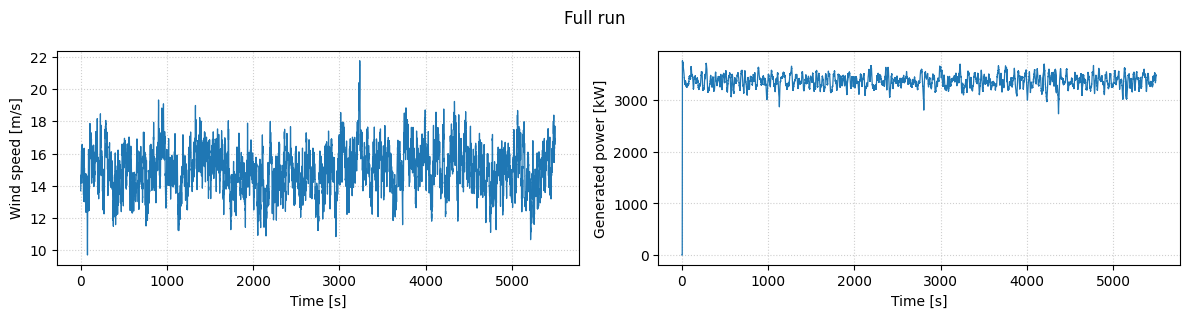

 Wind1VelX: min         9.70   max        21.77  [m/s]
    GenPwr: min         0.00   max      3766.00  [kW]


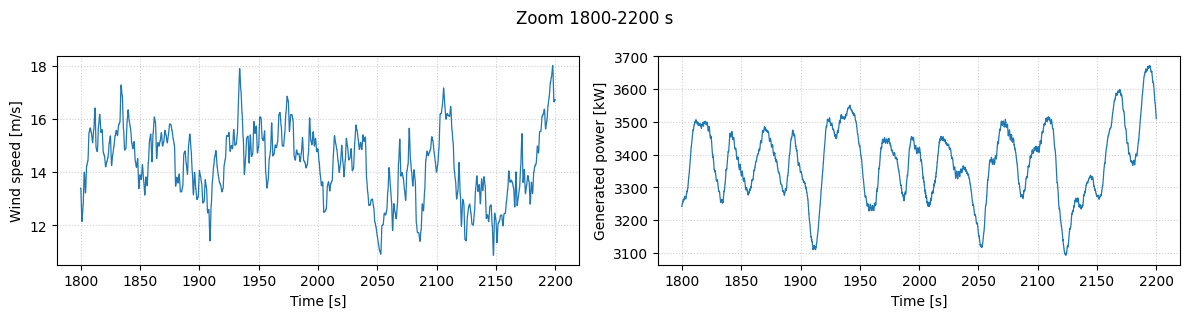

 Wind1VelX: min        10.88   max        18.00  [m/s]
    GenPwr: min      3093.00   max      3672.00  [kW]


In [6]:
plot(df, [("Wind1VelX", "Wind speed"), ("GenPwr", "Generated power")], "Full run")
plot(zoom, [("Wind1VelX", "Wind speed"), ("GenPwr", "Generated power")], f"Zoom {ZOOM[0]}-{ZOOM[1]} s")

## 2. Pitch

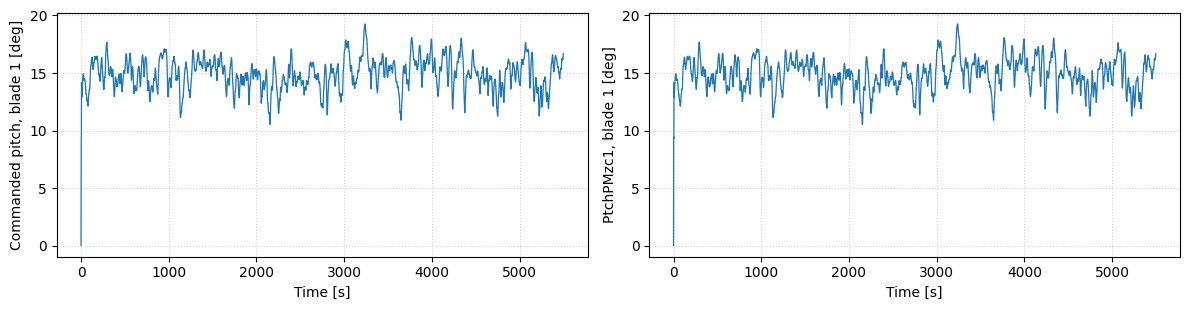

 BlPitchC1: min         0.02   max        19.27  [deg]
 PtchPMzc1: min         0.02   max        19.27  [deg]


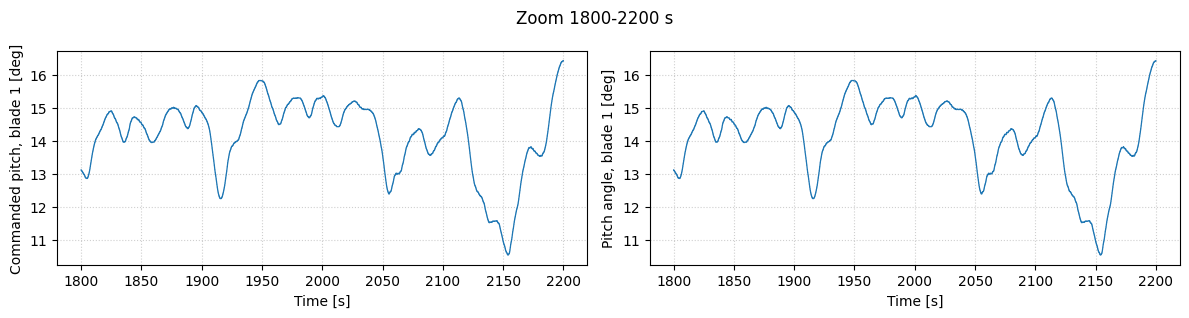

 BlPitchC1: min        10.53   max        16.42  [deg]
 BldPitch1: min        10.53   max        16.42  [deg]


In [7]:
plot(df, [("BlPitchC1", "Commanded pitch, blade 1"), ("PtchPMzc1", "PtchPMzc1, blade 1")])
plot(zoom, [("BlPitchC1", "Commanded pitch, blade 1"), ("BldPitch1", "Pitch angle, blade 1")],
     f"Zoom {ZOOM[0]}-{ZOOM[1]} s")

## 3. Rotor and generator

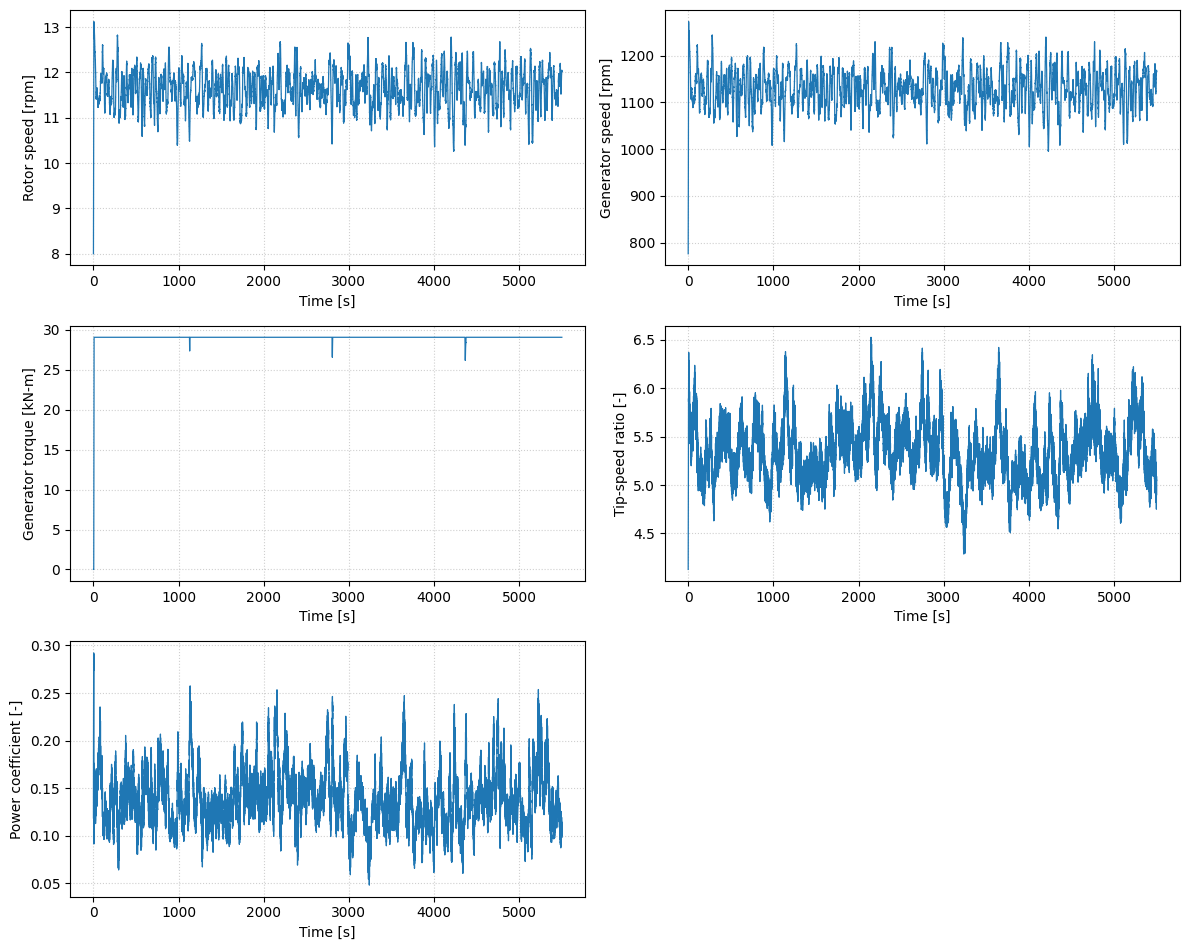

  RotSpeed: min         8.00   max        13.12  [rpm]
  GenSpeed: min       776.00   max      1273.00  [rpm]
     GenTq: min         0.00   max        29.08  [kN-m]
     RtTSR: min         4.13   max         6.53  [-]
  RtAeroCp: min         0.05   max         0.29  [-]


In [8]:
plot(df, [("RotSpeed", "Rotor speed"), ("GenSpeed", "Generator speed"),
          ("GenTq", "Generator torque"), ("RtTSR", "Tip-speed ratio"),
          ("RtAeroCp", "Power coefficient")])

## 4. Loads (from T_MIN)

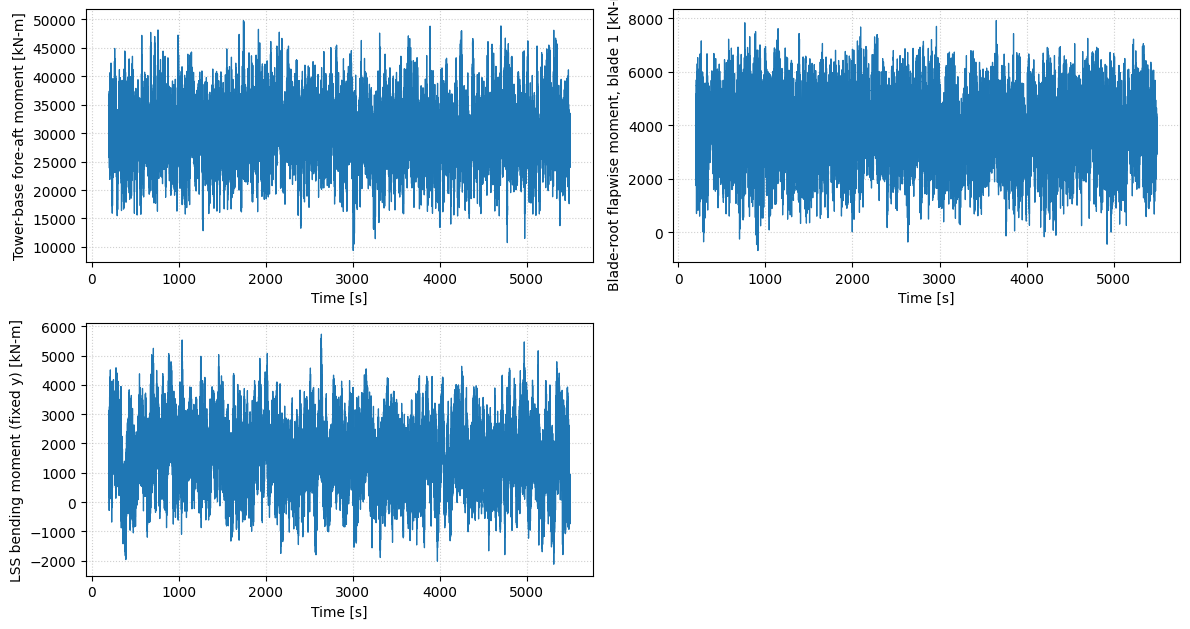

  TwrBsMyt: min      9355.00   max     49810.00  [kN-m]
  RootMyb1: min      -685.10   max      7922.00  [kN-m]
 LSSGagMys: min     -2120.00   max      5729.00  [kN-m]


In [9]:
plot(df[df["Time"] >= T_MIN],
     [("TwrBsMyt", "Tower-base fore-aft moment"), ("RootMyb1", "Blade-root flapwise moment, blade 1"),
      ("LSSGagMys", "LSS bending moment (fixed y)")])

## 5. Operating curves

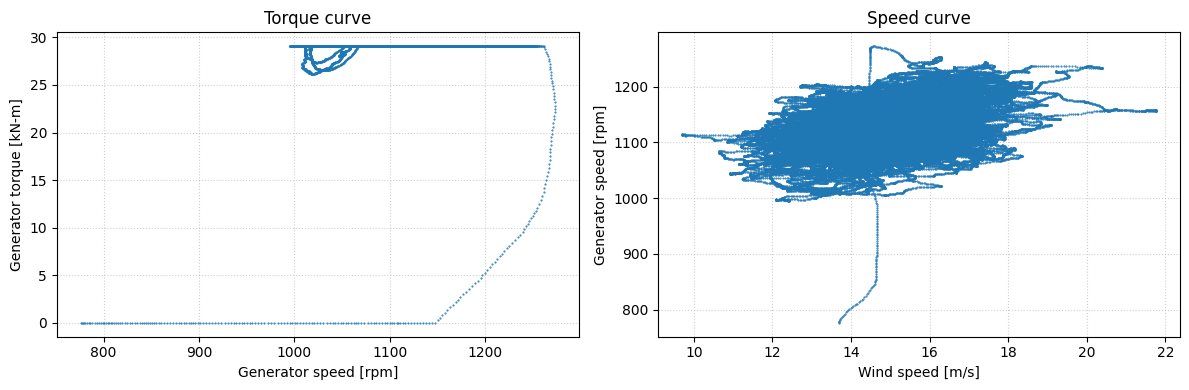

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(df["GenSpeed"], df["GenTq"], ".", ms=1)
axs[0].set_xlabel(f"Generator speed [{units['GenSpeed']}]"); axs[0].set_ylabel(f"Generator torque [{units['GenTq']}]")
axs[0].set_title("Torque curve")
axs[1].plot(df["Wind1VelX"], df["GenSpeed"], ".", ms=1)
axs[1].set_xlabel(f"Wind speed [{units['Wind1VelX']}]"); axs[1].set_ylabel(f"Generator speed [{units['GenSpeed']}]")
axs[1].set_title("Speed curve")
for ax in axs:
    ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

## 6. Statistics (T_MIN–T_MAX)
Scaled STD here uses the min–max range of the run itself; the paper normalizes with the ROSCO range,
so these values are only for tracking the run.

In [11]:
def scaled_std(x):
    span = x.max() - x.min()
    return float(((x - x.min()) / span).std()) if span else 0.0

rows = {}
for col in ["GenPwr", "TwrBsMyt", "RootMyb1"]:
    x = win[col]
    rows[col] = {"Mean": x.mean(), "STD": x.std(), "Scaled STD (own range)": scaled_std(x),
                 "Min": x.min(), "Max": x.max(), "Unit": units[col]}
stats = pd.DataFrame(rows).T

p = win["GenPwr"]
pitch = win["BldPitch1"].to_numpy()
hours = (win["Time"].iloc[-1] - win["Time"].iloc[0]) / 3600
print(f"Mean power error vs rated: {100 * (p.mean() - P_RATED) / P_RATED:+.2f} %")
print(f"Pitch travel: {np.abs(np.diff(pitch)).sum() / hours:.1f} deg/h")
print(f"Rotor speed max: {win['RotSpeed'].max():.3f} {units['RotSpeed']}")
stats.round(3)

Mean power error vs rated: -0.03 %
Pitch travel: 317.0 deg/h
Rotor speed max: 12.820 rpm


,Mean,STD,Scaled STD (own range),Min,Max,Unit
GenPwr,3368.998865,123.531963,0.12644,2737.0,3714.0,kW
TwrBsMyt,30253.617097,5038.929702,0.124556,9355.0,49810.0,kN-m
RootMyb1,3902.952819,1264.523083,0.146916,-685.1,7922.0,kN-m
